# Ordering commuting RZZ gates before compilation

This experiment asks whether ordering pair interactions in disjoint-qubit rounds changes the compiled circuit depth, duration or noisy results. RZZ gates in this cost layer commute, so changing their order preserves the ideal circuit. Each round below is a matching: no two pairs in it use the same SNP.

The comparison keeps the reads, angles, backend and transpiler settings fixed. It uses one simple greedy edge-coloring rule. A second backend is left for a later comparison.

## 1. Load the shared problem

This loads the fixed input, circuit builder, cost function and FakeManilaV2 snapshot used by the other experiments. The angles stay fixed in both arms.

In [1]:
from pathlib import Path
from qiskit.transpiler import PassManager
from qiskit.transpiler.passes import ALAPScheduleAnalysis, PadDelay

setup_path = Path('hardware_setup.ipynb')
if not setup_path.exists():
    setup_path = Path('hardware/hardware_setup.ipynb')
if not setup_path.exists():
    setup_path = Path('experiments/hardware/hardware_setup.ipynb')
%run $setup_path

print('Backend:', backend.name)
print('Active SNP pairs:', len(edges))

5 SNPs, 9 active interactions, backend: fake_manila
Exact minimum: 1
The reversed SNP order keeps the same ideal output distribution.
Backend: fake_manila
Active SNP pairs: 9


## 2. Build disjoint-pair rounds

The baseline uses the shared builder's original pair order. The second circuit sorts the same active pairs into greedy rounds: each pair goes into the earliest round where both SNPs are free. The grouping changes order only; it does not change any coupling or angle.

In [2]:
matching_rounds = []
for edge in edges:
    for one_round in matching_rounds:
        used_snps = {snp for pair in one_round for snp in pair}
        if not used_snps.intersection(edge):
            one_round.append(edge)
            break
    else:
        matching_rounds.append([edge])

round_edges = [edge for one_round in matching_rounds for edge in one_round]
assert sorted(round_edges) == sorted(edges)

round_table = pd.DataFrame([
    {'round': index, 'pairs': ', '.join(f'SNP{i + 1}–SNP{j + 1}' for i, j in one_round)}
    for index, one_round in enumerate(matching_rounds, start=1)
])
display(round_table)

,round,pairs
0,1,"SNP1–SNP2, SNP3–SNP4"
1,2,"SNP1–SNP3, SNP2–SNP4"
2,3,"SNP1–SNP4, SNP2–SNP3"
3,4,SNP1–SNP5
4,5,SNP3–SNP5
5,6,SNP4–SNP5


The compiler already schedules independent instructions when dependencies allow. This explicit edge order tests whether giving it disjoint RZZ groups as a starting order helps after routing to FakeManila's line-shaped coupling map. The transpiler may still choose the final route and gate sequence.

In [3]:
def make_circuit_with_edges(edge_order):
    circuit = QuantumCircuit(n, n)
    circuit.h(range(n))
    for gamma, beta in zip(gammas, betas):
        for i, j in edge_order:
            angle = 2 * gamma * couplings[i, j] / scale
            circuit.rzz(angle, i, j)
        circuit.rx(2 * beta, range(n))
    for snp in range(n):
        circuit.measure(snp, snp)
    return circuit

circuits = {
    'Original edge order': make_circuit(),
    'Greedy disjoint rounds': make_circuit_with_edges(round_edges),
}

if ideal is not None:
    for circuit in circuits.values():
        assert np.allclose(logical_probabilities(circuit), ideal)
    print('Both orders have the same ideal output probabilities.')
else:
    print('Exact probability check skipped above 12 SNPs.')

Both orders have the same ideal output probabilities.


## 3. Compile both orders with shared controls

Each circuit uses the same physical layout, optimization level and SABRE routing method. The same 20 transpiler seeds are used for both, so resource differences are paired by seed. Duration is estimated after Qiskit's ALAP scheduling and delay padding for the backend target.

In [4]:
physical = list(range(n))
compiled = {}
resource_rows = []
for method, circuit in circuits.items():
    for seed in compile_seeds:
        manager = generate_preset_pass_manager(
            backend=backend,
            optimization_level=2,
            initial_layout=physical,
            routing_method='sabre',
            seed_transpiler=seed,
        )
        routed = manager.run(circuit)
        compiled[method, seed] = routed
        scheduled = PassManager([
            ALAPScheduleAnalysis(target=backend.target),
            PadDelay(target=backend.target),
        ]).run(routed)
        resource_rows.append({
            'method': method,
            'seed': seed,
            'duration (dt)': scheduled.estimate_duration(backend.target, unit='dt'),
            **resources(routed),
        })

resource_table = pd.DataFrame(resource_rows)
display(resource_table.groupby('method', sort=False)[
    ['2q gates', '2q depth', 'depth', 'duration (dt)']
].agg(['median', 'min', 'max']))

2q gates         2q depth          depth          \
                         median min max   median min max median min max   
method                                                                    
Original edge order        28.0  26  28     23.0  21  23   57.0  57  57   
Greedy disjoint rounds     36.0  36  36     29.0  29  29   52.0  52  52   

                       duration (dt)                
                              median    min    max  
method                                              
Original edge order          67632.0  63920  67632  
Greedy disjoint rounds       76496.0  76496  76496

## 4. Read the resource comparison

Fewer two-qubit gates, lower depth and shorter duration can each help, but they are different measures. The plots show the distribution over compilation seeds; the median is the line in each box and the triangle is the mean.

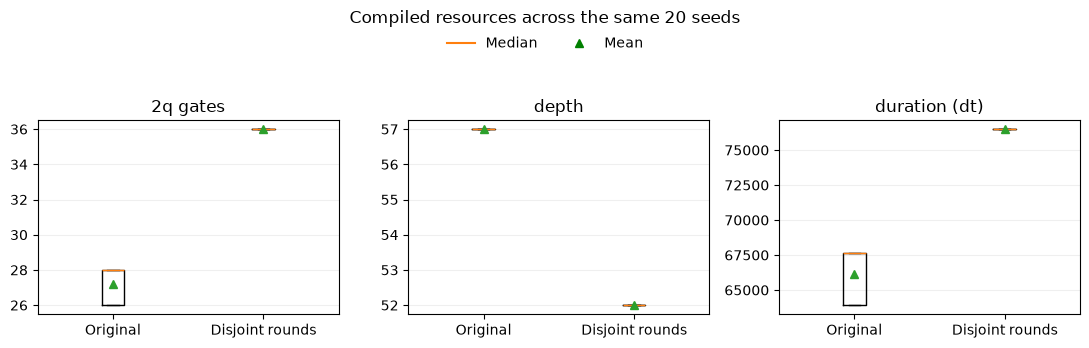

In [5]:
method_order = list(circuits)
fig, axes = plt.subplots(1, 3, figsize=(11, 3.5))
for ax, metric in zip(axes, ['2q gates', 'depth', 'duration (dt)']):
    data = [resource_table.loc[resource_table.method == name, metric]
            for name in method_order]
    ax.boxplot(data, tick_labels=['Original', 'Disjoint rounds'], showmeans=True)
    ax.set_title(metric)
    ax.grid(axis='y', alpha=.2)
fig.suptitle('Compiled resources across the same 20 seeds')
boxplot_legend(fig)
fig.tight_layout(rect=(0, 0, 1, 0.86))
plt.show()

## 5. Compare noisy samples

For each of three shared compilation seeds, both arms use the same three simulator repeat seeds and 2,048 shots per run. The FakeManilaV2 Aer model adds gate and readout noise; it does not add a separate idle-time error for scheduled delays, so duration is reported as its own resource measure.

In [6]:
if backend.num_qubits > 16:
    raise ValueError('For a larger backend, turn off noise or choose a smaller simulator.')

simulator = AerSimulator.from_backend(backend, max_parallel_threads=1)
noisy_rows = []
for seed in noise_seeds:
    for repeat in range(noise_repeats):
        simulator_seed = 90_000 + seed * 100 + repeat
        for method in method_order:
            counts = simulator.run(
                compiled[method, seed],
                shots=shots,
                seed_simulator=simulator_seed,
            ).result().get_counts()
            noisy_rows.append({
                'method': method,
                'seed': seed,
                'repeat': repeat,
                'shots': sum(counts.values()),
                **score(counts),
            })

noisy_results = pd.DataFrame(noisy_rows)
display(noisy_results.groupby('method', sort=False)[
    ['shots', 'mean cost', 'optimum frequency']
].agg(['mean', 'std']))

shots      mean cost           optimum frequency  \
                          mean  std      mean       std              mean   
method                                                                      
Original edge order     2048.0  0.0  9.431424  0.123323          0.285482   
Greedy disjoint rounds  2048.0  0.0  9.489041  0.189146          0.271484   

                                  
                             std  
method                            
Original edge order     0.009980  
Greedy disjoint rounds  0.015714

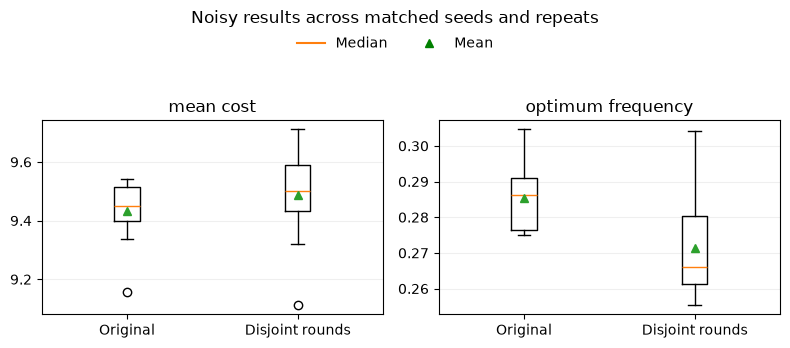

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3.5))
for ax, metric in zip(axes, ['mean cost', 'optimum frequency']):
    data = [noisy_results.loc[noisy_results.method == name, metric]
            for name in method_order]
    ax.boxplot(data, tick_labels=['Original', 'Disjoint rounds'], showmeans=True)
    ax.set_title(metric)
    ax.grid(axis='y', alpha=.2)
fig.suptitle('Noisy results across matched seeds and repeats')
boxplot_legend(fig)
fig.tight_layout(rect=(0, 0, 1, 0.86))
plt.show()

## What did I find?

The disjoint-round order lowered median depth from 57 to 52, but raised median two-qubit gates from 28 to 36 and estimated duration from 67,632 to 76,496 dt. In the noisy pilot, mean cost changed from 9.43 to 9.49 and optimum frequency from 0.285 to 0.271. So the shallower circuit did not improve noisy results here. These are nine repeats on one FakeManilaV2 snapshot; another backend is left for later.

In [8]:
summary = noisy_results.groupby('method')[['mean cost', 'optimum frequency']].mean()
resource_medians = resource_table.groupby('method')[['2q gates', 'depth', 'duration (dt)']].median()
base_name, round_name = method_order
print('Median resource change (disjoint rounds − original):')
for metric in ['2q gates', 'depth', 'duration (dt)']:
    print(f'  {metric}: {resource_medians.loc[round_name, metric] - resource_medians.loc[base_name, metric]:+.0f}')
print('Mean-cost change (disjoint rounds − original):',
      f"{summary.loc[round_name, 'mean cost'] - summary.loc[base_name, 'mean cost']:+.3f}")
print('Optimum-frequency change (disjoint rounds − original):',
      f"{summary.loc[round_name, 'optimum frequency'] - summary.loc[base_name, 'optimum frequency']:+.3f}")

Median resource change (disjoint rounds − original):
  2q gates: +8
  depth: -5
  duration (dt): +8864
Mean-cost change (disjoint rounds − original): +0.058
Optimum-frequency change (disjoint rounds − original): -0.014


### References

- [IBM Quantum: Advanced techniques for QAOA](https://quantum.cloud.ibm.com/docs/en/tutorials/advanced-techniques-for-qaoa) — demonstrates greedy edge coloring to order commuting RZZ gates in a QAOA circuit.
- [Venturelli et al., *Temporal Planning for Compilation of Quantum Approximate Optimization Circuits* (IJCAI 2017)](https://doi.org/10.24963/ijcai.2017/620) — studies scheduling and compiling QAOA circuits with many commuting gates.
- [Venturelli et al., *Two-step approach to scheduling quantum circuits*](https://arxiv.org/abs/1708.00023) — examines edge-coloring and hardware-aware schedules, including QAOA on a line.